In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

data = pd.read_parquet("../data/cleaned/bitcoin_cleaned.parquet")

print("Shape:", data.shape)
print("From", data["timestamp"].iloc[0], "to", data["timestamp"].iloc[-1])
data.head()

Shape: (8760, 6)
From 2025-10-23 21:00:00 to 2026-10-23 20:00:00


,timestamp,open,high,low,price_usd,volume
0,2025-10-23 21:00:00,109524.81,109727.22,109380.12,109532.97,424.08473
1,2025-10-23 22:00:00,109532.96,110158.37,109517.37,109943.94,443.21336
2,2025-10-23 23:00:00,109943.95,110099.17,109839.00,110078.18,259.37538
3,2025-10-24 00:00:00,110078.19,110709.22,109983.93,110500.28,531.07612
4,2025-10-24 01:00:00,110500.29,110665.53,110141.38,110585.08,371.99990


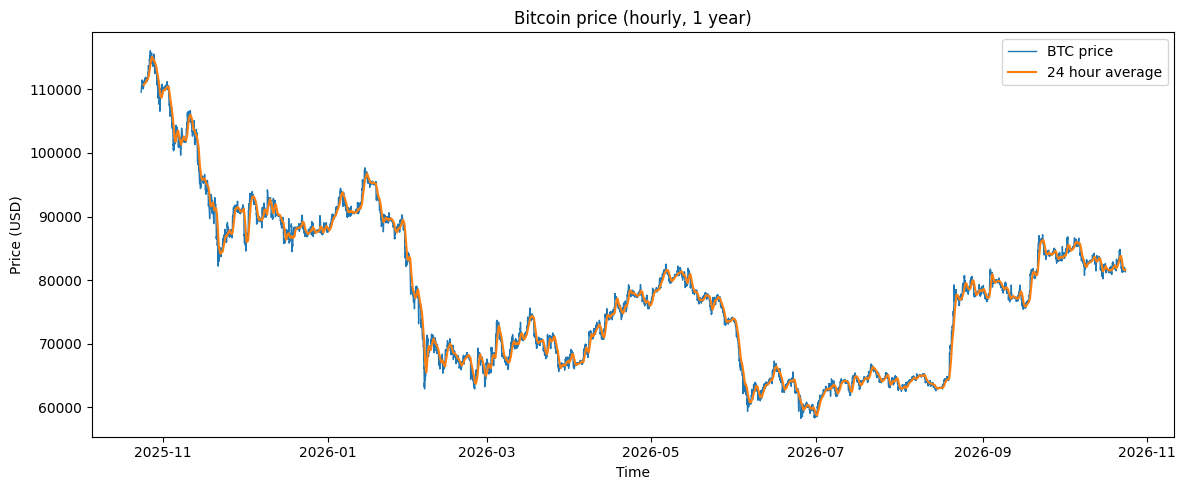

In [20]:
os.makedirs("../plots", exist_ok=True)

plot_data = data.copy()
plot_data["average_24h"] = plot_data["price_usd"].rolling(24).mean()

plt.figure(figsize=(12, 5))
plt.plot(plot_data["timestamp"], plot_data["price_usd"], label="BTC price", linewidth=1)
plt.plot(plot_data["timestamp"], plot_data["average_24h"], label="24 hour average", linewidth=1.5)
plt.title("Bitcoin price (hourly, 1 year)")
plt.xlabel("Time")
plt.ylabel("Price (USD)")
plt.legend()
plt.tight_layout()
plt.savefig("../plots/bitcoin_price.png", dpi=150)
plt.show()

In [21]:
# keep a copy of the prices for the website later
prices = data[["timestamp", "price_usd", "volume"]].copy()

# how much the price changed in the last 1, 2, 3, 6, 24 hours
data["return_1"] = data["price_usd"].pct_change(1)
data["return_2"] = data["price_usd"].pct_change(2)
data["return_3"] = data["price_usd"].pct_change(3)
data["return_6"] = data["price_usd"].pct_change(6)
data["return_24"] = data["price_usd"].pct_change(24)

# the return from 1 hour ago
data["return_lag_1"] = data["return_1"].shift(1)

# is price above or below its recent average
data["mean_6"] = data["price_usd"].rolling(6).mean()
data["mean_24"] = data["price_usd"].rolling(24).mean()
data["price_vs_mean_6"] = data["price_usd"] / data["mean_6"]
data["price_vs_mean_24"] = data["price_usd"] / data["mean_24"]

# how wild the price was in the last 24 hours
data["volatility_24"] = data["return_1"].rolling(24).std()

# how much the volume changed
data["volume_change"] = data["volume"].pct_change(1)

features = [
    "return_1", "return_2", "return_3", "return_6", "return_24",
    "return_lag_1", "price_vs_mean_6", "price_vs_mean_24",
    "volatility_24", "volume_change"
]

print("Features created:", len(features))

Features created: 10


In [22]:
data = data.replace([np.inf, -np.inf], np.nan)
latest_row = data[features].iloc[[-1]]
latest_time = data["timestamp"].iloc[-1]

# target: 1 = next hour price goes up, 0 = it doesn't
data["future_price"] = data["price_usd"].shift(-1)
data["target"] = (data["future_price"] > data["price_usd"]).astype(int)

data = data.dropna().reset_index(drop=True)

print("Prepared dataset shape:", data.shape)
print("Latest row time:", latest_time)
print(data["target"].value_counts(normalize=True).round(3))

Prepared dataset shape: (8735, 20)
Latest row time: 2026-10-23 20:00:00
target
1    0.5
0    0.5
Name: proportion, dtype: float64


In [23]:
X = data[features]
y = data["target"]

split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train:", data["timestamp"].iloc[0], "to", data["timestamp"].iloc[split_index - 1])
print("Test:", data["timestamp"].iloc[split_index], "to", data["timestamp"].iloc[-1])

Training rows: 6988
Testing rows: 1747
Train: 2025-10-24 21:00:00 to 2026-08-12 00:00:00
Test: 2026-08-12 01:00:00 to 2026-10-23 19:00:00


In [24]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=50,
    random_state=42
)

model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [25]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
balanced = balanced_accuracy_score(y_test, predictions)
baseline = y_test.mean()

print("Accuracy:", round(accuracy, 4))
print("Balanced accuracy:", round(balanced, 4))
print("Always-UP baseline:", round(baseline, 4))
print()
print(classification_report(y_test, predictions, target_names=["NOT UP", "UP"]))
print(confusion_matrix(y_test, predictions))

Accuracy: 0.5192
Balanced accuracy: 0.5188
Always-UP baseline: 0.5089

              precision    recall  f1-score   support

      NOT UP       0.51      0.50      0.50       858
          UP       0.53      0.54      0.53       889

    accuracy                           0.52      1747
   macro avg       0.52      0.52      0.52      1747
weighted avg       0.52      0.52      0.52      1747

[[428 430]
 [410 479]]


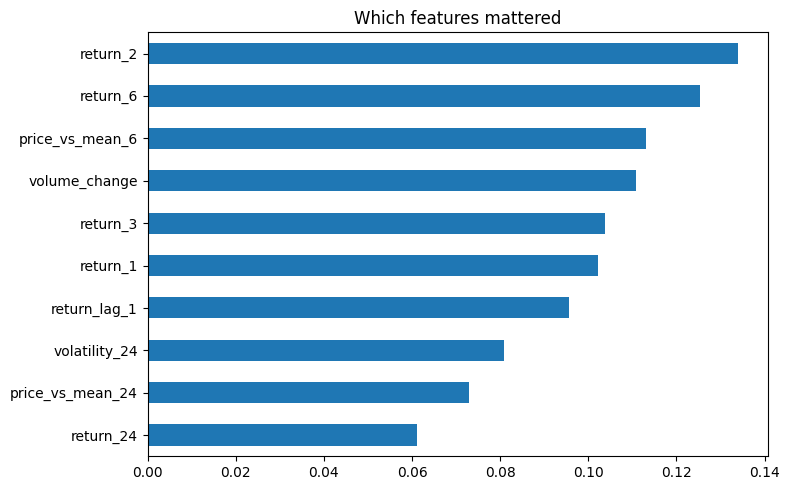

In [26]:
importance = pd.Series(model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Which features mattered")
plt.tight_layout()
plt.savefig("../plots/feature_importance.png", dpi=150)
plt.show()

In [27]:
os.makedirs("../docs", exist_ok=True)

# next hour prediction
prob_up = float(model.predict_proba(latest_row)[0][1])

if prob_up > 0.55:
    signal = "UP"
elif prob_up < 0.45:
    signal = "DOWN"
else:
    signal = "NO CLEAR SIGNAL"

# trend numbers
current_price = float(prices["price_usd"].iloc[-1])

def change(hours):
    old_price = float(prices["price_usd"].iloc[-1 - hours])
    return round((current_price / old_price - 1) * 100, 2)

avg_24 = float(prices["price_usd"].tail(24).mean())
avg_168 = float(prices["price_usd"].tail(168).mean())

if current_price > avg_24 and avg_24 > avg_168:
    trend = "Uptrend"
elif current_price < avg_24 and avg_24 < avg_168:
    trend = "Downtrend"
else:
    trend = "Sideways / mixed"

volume_24h = float(prices["volume"].tail(24).sum())

# last 30 days of prices for the chart
chart = prices.tail(720)

output = {
    "updated": str(latest_time),
    "current_price": round(current_price, 2),
    "volume_24h_btc": round(volume_24h, 2),
    "volume_24h_usd": round(float((prices["price_usd"] * prices["volume"]).tail(24).sum()), 0),
    "change_24h": change(24),
    "change_7d": change(168),
    "change_30d": change(720),
    "trend": trend,
    "next_hour_prob_up": round(prob_up * 100, 1),
    "signal": signal,
    "model_accuracy": round(accuracy * 100, 1),
    "model_balanced_accuracy": round(balanced * 100, 1),
    "baseline_always_up": round(float(baseline) * 100, 1),
    "test_rows": int(len(X_test)),
    "chart_times": [str(t) for t in chart["timestamp"]],
    "chart_prices": [round(float(p), 2) for p in chart["price_usd"]]
}

with open("../docs/data.json", "w") as file:
    json.dump(output, file)

print("Exported docs/data.json")
print("Signal:", signal, "| Probability UP:", output["next_hour_prob_up"], "%")
print("Trend:", trend)

Exported docs/data.json
Signal: UP | Probability UP: 55.5 %
Trend: Downtrend
